# Project C: Generative modeling of the Ising model

### Motivation

**The Ising model** is a model of magnetism: a grid of tiny magnets ("spins"), each pointing either up (+1) or down (−1).

Low temperature: the spins tend to align in the same direction to minimize energy, so the whole lattice locks into one dominant direction (mostly up, or mostly down). This is the ordered phase - large magnetization (ferromagnetic).

High temperature: thermal fluctuations cause the spins to point in random directions, canceling each other out. This is the disordered phase - magnetization near zero: $M\rightarrow0$ (paramagnetic).

There's a sharp switch between these two behaviors at a precise critical temperature 
$T_c​≈2.269$ - this where the phase transition takes place, the same kind of physics behind real magnets losing their magnetism when heated.

As mentioned in the assignment, this project focuses on training a model on Ising lattice configurations to *produce* new spin configurations and see if **those** obey the physics.


Our end goal is a to create generator whose output depends on the **temperature** $T$ which also obeys the physics.

### The work flow

**Simulating** -  by using the Metropolis Monte-Carlo simulator, we will produce a dataset of real Ising configurations at a chosen temperature T. This will be the training data for the diffusion model.

**Training** - we will then train a diffusion model on that simulated dataset.

**Generating** - then we will start to generate configurations with the trained model. Starting from pure random noise, we will use the trained denoiser to produce new configurations.

**Comparing** - we will compare the generated outputs against the simulated ones - first - visually, then statistically, using the physical-statistics battery (magnetization distribution, energy per spin), to check whether the model learned the actual physics or just something that looks superficially similar.

---
## Part 1: Creating Two Diffusion Models

### Step 1 is **The forward process - turning data into noise**

Generating function

In [ ]:
import numpy as np

# ---- fast, vectorized Metropolis simulator (checkerboard updates) ----
def ising_config(T, L=16, n_sweeps=120):
    """One equilibrated 2-D Ising configuration at temperature T (periodic boundaries).
    Vectorized checkerboard Metropolis -> much faster than a per-site loop.
    Returns an (L, L) array of +-1 spins. Tc (exact, infinite lattice) = 2.269.
    Increase n_sweeps near Tc, where correlation times grow (critical slowing down)."""
    s = np.random.choice([-1, 1], size=(L, L)).astype(np.float32)
    ii, jj = np.indices((L, L)); even = (ii + jj) % 2 == 0
    for _ in range(n_sweeps):
        for mask in (even, ~even):                      # update the two sublattices in turn
            nb = (np.roll(s, 1, 0) + np.roll(s, -1, 0) + np.roll(s, 1, 1) + np.roll(s, -1, 1))
            flip = (np.random.rand(L, L) < np.exp(-2 * s * nb / T)) & mask
            s[flip] *= -1
    return s

**The set up:**

* Temperature: T=2.0 which is clearly below the critical temperature $T_c≈2.269$ so the physics is in the ordered/bimodal regime, but not so cold that every config looks identical.

* Lattice size: $L=16$

* Number of training configurations: N=2000 is enough to train a small diffusion model on a 16×16 lattice in a reasonable time frame.

In [ ]:
# Generating training data: real Ising configurations at T = 2.0
T_train = 2.0        # below Tc (~2.269) -> ordered, bimodal magnetization
L = 16
N_train = 2000 

configs_list = []
for _ in range(N_train):
    configs_list.append(ising_config(T_train, L=L))

configs_for_train = np.stack(configs_list)
print(configs_for_train.shape)   # should be (2000, 16, 16)

(2000, 16, 16)


Plotting a few examples, including the mean of the magnetization in order to see if our simulated samples actually obey the physics in order to be a comperable reference to the generated samples later on. In this case, we expect to see bimodal magnetization distribution.

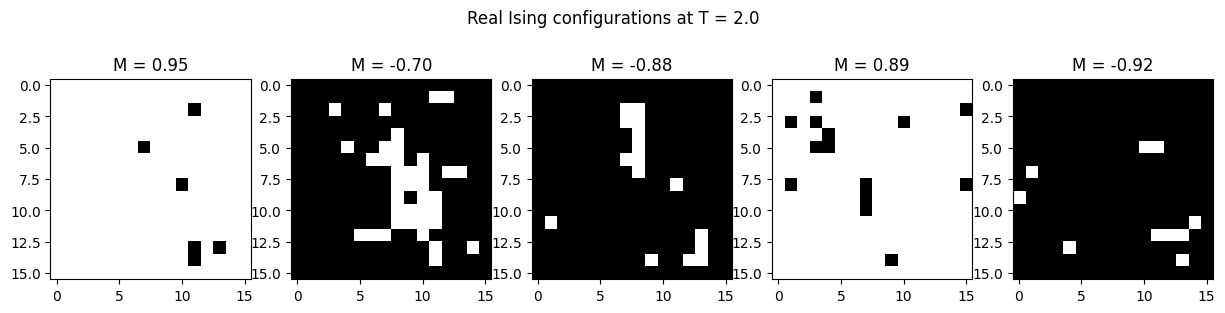

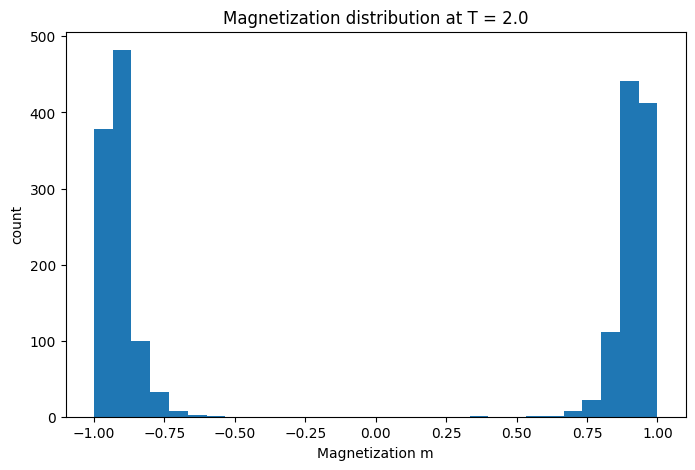

mean |m| = 0.912
fraction with m > 0: 0.50   fraction with m < 0: 0.50


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Plot a few example Ising configurations (same imshow style as HW9, 2.2)
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))
for i, ax in enumerate(axes):
    ax.imshow(configs_for_train[i], cmap='gray')
    ax.set_title(f"M = {configs_for_train[i].mean():.2f}")
plt.suptitle(f"Real Ising configurations at T = {T_train}")
plt.show()

# Magnetization distribution - checking it's bimodal (peaks near +-M0), per the physics discussion
magnetizations = configs_for_train.mean(axis=(1, 2))
plt.figure(figsize=(8, 5))
plt.hist(magnetizations, bins=30)
plt.xlabel('Magnetization m')
plt.ylabel('count')
plt.title(f'Magnetization distribution at T = {T_train}')
plt.show()

print(f"mean |m| = {np.abs(magnetizations).mean():.3f}")
print(f"fraction with m > 0: {(magnetizations > 0).mean():.2f}   fraction with m < 0: {(magnetizations < 0).mean():.2f}")

Starting with the forward process - turning data into noise.
$$
x_t = \sqrt{\bar{\alpha}_t}\, x_0 + \sqrt{1 - \bar{\alpha}_t}\;\epsilon, \qquad \epsilon \sim \mathcal{N}(0, I),
$$
A fixed recipe for adding noise.

In [4]:
import torch 

# Forward-process noise schedule: T small steps, beta increasing, alpha decreasing -> more noise in each step.
n_steps = 300
betas = torch.linspace(1e-4, 0.04, n_steps) # schedule
alphas = 1 - betas 
alpha_bar = torch.cumprod(alphas, dim=0) # cumulative product = alpha_t in the formula

print(betas[:5], betas[-5:])         # should start ~1e-4, end ~0.02
print(alpha_bar[0], alpha_bar[-1])   # should start close to 1, end close to 0

tensor([1.0000e-04, 2.3344e-04, 3.6689e-04, 5.0033e-04, 6.3378e-04]) tensor([0.0395, 0.0396, 0.0397, 0.0399, 0.0400])
tensor(0.9999) tensor(0.0022)


In order to see that this process has worked, we will apply over the first sample, demonstrating over several steps.

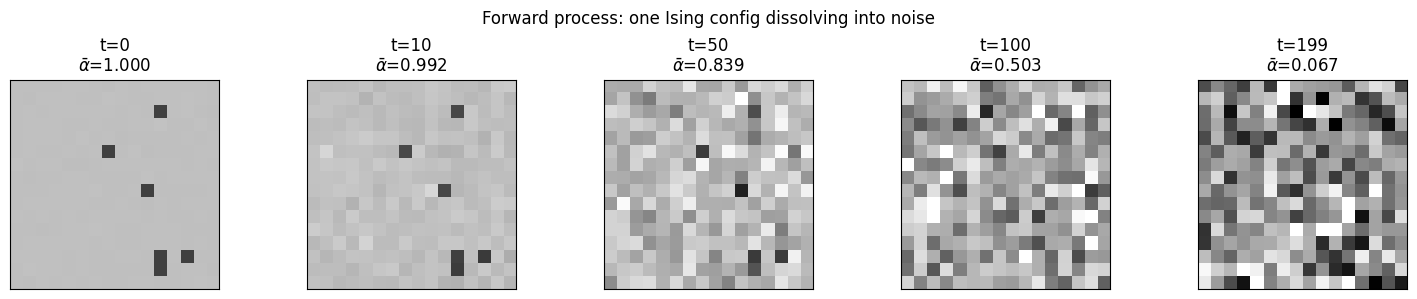

In [5]:
x0 = torch.tensor(configs_for_train[0], dtype=torch.float32)   # one real config

ts_to_show = [0, 10, 50, 100, 199]
fig, axes = plt.subplots(1, len(ts_to_show), figsize=(15, 3))

torch.manual_seed(0)
for ax, t in zip(axes, ts_to_show):
    noise = torch.randn_like(x0)
    ab = alpha_bar[t]
    xt = torch.sqrt(ab) * x0 + torch.sqrt(1 - ab) * noise
    ax.imshow(xt.numpy(), cmap='gray', vmin=-2, vmax=2)
    ax.set_title(f"t={t}\n$\\bar\\alpha$={ab:.3f}")
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Forward process: one Ising config dissolving into noise")
plt.tight_layout(); plt.show()

### Step 2 is **The reverse process**

This is where the learning happens. We train a neural network to **undo** one step of noising.
This network is called the **denoiser** - This is the reverse process: given a noisy lattice $x_t$ and the timestep $t$, it has to predict the noise $\epsilon$ that was mixed in to produce it.

**Inputs**: the noisy config $x_t$ (a $16\times16$ grid of numbers), and the timestep $t$ (a single integer telling the network "how noisy is this, roughly" - since noise at $t=5$ looks very different from noise at $t=190$, and the network needs to know which regime it's in to denoise correctly).

**Output**: a predicted noise map, same shape as $x_t$ ($16\times16$).

**Training objective**: simple mean-squared error between predicted noise and actual noise:
$$
\mathcal{L} = \mathbb{E}_{x_0, t, \epsilon}\;\big\| \epsilon - \epsilon_\theta(x_t, t)\big\|^2.
$$

This is a regression problem - MSE. The prediction is the noise in a certain step: 
$$
x_t = \sqrt{\alpha_t}\, x_0 + \sqrt{1 - \alpha_t}\;\epsilon, \qquad \epsilon \sim \mathcal{N}(0, I),
$$

In [ ]:
import torch.nn as nn

# convolutional denoiser - extracting the noise
class ConvDenoiser(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(2, hidden, kernel_size=3, padding=1, padding_mode='circular'), nn.SiLU(), # the 2 here is the input which is 2 grids stacked together (spin, noise)
            # circular padding treats the left edge as neighboring the right edge, matching the simulator's actual periodic boundary conditions
            nn.Conv2d(hidden, hidden, kernel_size=3, padding=1, padding_mode='circular'), nn.SiLU(),
            nn.Conv2d(hidden, hidden, kernel_size=3, padding=1, padding_mode='circular'), nn.SiLU(),
            nn.Conv2d(hidden, 1, kernel_size=3, padding=1, padding_mode='circular'),
        )

    def forward(self, x, t, n_steps):
        B, _, L, _ = x.shape # 'x' is the noisy grid, 'B' is the batch size, 'L' is the grid size
        t_channel = (t.float() / n_steps).view(B, 1, 1, 1).expand(B, 1, L, L) # creating the noise grid - taking the single normalized noise-level number and copying it into every cell of a grid
        h = torch.cat([x, t_channel], dim=1) # stacking the two grids together
        return self.net(h) # (B, 1, L, L) predicted noise

In [7]:
# MLP denoiser

class MLPDenoiser(nn.Module):
    def __init__(self, L=16, hidden=512):
        super().__init__()
        self.L = L
        self.net = nn.Sequential(
            nn.Linear(L * L + 1, hidden), nn.SiLU(), # input is a noisy grid and a noise scalar
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, L * L),
        )

    def forward(self, x, t, n_steps):
        B = x.shape[0]
        flat = x.view(B, -1) # (B, 1, L, L) -> (B, L*L): flattening the noisy input, throwing away grid structure
        t_norm = (t.float() / n_steps).view(B, 1) # single normalized scalar number per example
        h = torch.cat([flat, t_norm], dim=1) # (B, L*L + 1) combining flat noisy input with "how noisy it is"
        out = self.net(h) # (B, L*L) the stack of nn.Linear + nn.SiLU layers, each one full of weights (numbers that started random, and have been slowly adjusted by training) on the input we inserted. This is where computation actually happens
        return out.view(B, 1, self.L, self.L) # reshape prediction back to a grid for the loss/loop to use

Both denoisers, regardless of architecture, have the same job: take in a noisy grid (plus a timestep), and output a predicted noise map, same shape as the input.

#### Training Loop
We will create the training loop as a function which will fit for the CNN and the MLP later on. The loop is based on examples from the lecture.

In [ ]:
def train_denoiser(model, X, alpha_bar, n_steps, n_epochs=3000, batch_size=128, lr=1e-3, print_every=500):
    """Trains any denoiser with forward(x, t, n_steps) on data X (N,1,L,L)."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(n_epochs):
        opt.zero_grad()
        idx = torch.randint(0, len(X), (batch_size,)) # picking batch size of random indices
        x0 = X[idx] # grabbing those 128 real, clean configs
        t = torch.randint(0, n_steps, (batch_size,)) # picking a *random* noise-level t for each of the 128, so that the network becomes good at handling every noise level, in no particular order
        noise = torch.randn_like(x0) # generating the actual random noise to mix in (ϵ)
        ab = alpha_bar[t].view(-1, 1, 1, 1) # look up alpha_bar for each t, reshape to broadcast over the (1,L,L) grid
        xt = torch.sqrt(ab) * x0 + torch.sqrt(1 - ab) * noise # forward process: mixing signal and noise per the formula
        pred_noise = model(xt, t, n_steps) # asking the denoiser (CNN\MLP) to guess what noise was added, input is noisy grid and time stamp
        loss = ((pred_noise - noise) ** 2).mean() # comparing guess to the real noise (mean squared error)
        loss.backward()  # computing gradients of the loss w.r.t. every weight
        opt.step() # nudging the weights to reduce the loss
        if epoch % print_every == 0:
            print(f"epoch {epoch:4d} | noise-prediction MSE {loss.item():.4f}")
    print(f"Done training | Final MSE {loss.item():.4f}")

In [28]:
X = torch.tensor(configs_for_train, dtype=torch.float32).unsqueeze(1)
cnn_denoiser = ConvDenoiser(hidden=64)
train_denoiser(cnn_denoiser, X, alpha_bar, n_steps)

epoch    0 | noise-prediction MSE 1.0095
epoch  500 | noise-prediction MSE 0.0884
epoch 1000 | noise-prediction MSE 0.0599
epoch 1500 | noise-prediction MSE 0.0549
epoch 2000 | noise-prediction MSE 0.0434
epoch 2500 | noise-prediction MSE 0.0479
Done training | Final MSE 0.0374


In [29]:
# Saving the model's learned weights to a .pth file
torch.save(cnn_denoiser.state_dict(), 'cnn_denoiser_weights.pth')

In [30]:
# Initialize a new instance of the model architecture
loaded_denoiser_cnn = ConvDenoiser(hidden=64)

# Load the previously saved weights into the model
loaded_denoiser_cnn.load_state_dict(torch.load('cnn_denoiser_weights.pth'))

<All keys matched successfully>

In [32]:
mlp_denoiser = MLPDenoiser(L=16, hidden=512)
train_denoiser(mlp_denoiser, X, alpha_bar, n_steps, n_epochs=3000, batch_size=128, lr=1e-3)

epoch    0 | noise-prediction MSE 0.9890
epoch  500 | noise-prediction MSE 0.4508
epoch 1000 | noise-prediction MSE 0.3654
epoch 1500 | noise-prediction MSE 0.3534
epoch 2000 | noise-prediction MSE 0.3286
epoch 2500 | noise-prediction MSE 0.3174
Done training | Final MSE 0.2673


In [33]:
# Saving the model's learned weights to a .pth file
torch.save(mlp_denoiser.state_dict(), 'mlp_denoiser_weights.pth')

In [34]:
# Initialize a new instance of the model architecture
loaded_denoiser_mlp = MLPDenoiser(L=16, hidden=512)

# Load the previously saved weights into the model
loaded_denoiser_mlp.load_state_dict(torch.load('mlp_denoiser_weights.pth'))

<All keys matched successfully>

### Step 3 - Sampling: generating new configurations from noise

Once the denoiser is trained, we can reverse the forward process (which is mixing data with noise) to generate brand-new Ising configurations, starting from nothing but random noise.

As in the lecture: we trained the network to predict the noise $\epsilon_\theta(x_t, t)$ that
was mixed into $x_t$. Since the forward process was $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$, predicting the noise is equivalent to predicting the clean configuration - they're related by simple algebra:

$$
\hat x_0 = \frac{1}{\sqrt{\bar\alpha_t}}\Big(x_t - \sqrt{1-\bar\alpha_t}\,\epsilon_\theta(x_t,t)\Big).
$$

Rather than jumping straight to $\hat x_0$ in one giant step (which would lose diversity and
collapse every sample toward the same output), each reverse step removes only the noise
attributable to *that* step. Working this out gives the DDPM update rule:

$$
x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t,t)\Big) + \sqrt{\beta_t}\,z,\qquad z\sim\mathcal N(0,I),
$$

with the injected noise term $\sqrt{\beta_t}\,z$ added back for every step except the very last one ($t=0$). This keeps the reverse process stochastic, so repeated sampling runs explore the whole data distribution rather than every run collapsing onto the same single output.

In [ ]:
@torch.no_grad()
def sample(model, n, n_steps, alphas, alpha_bar, betas, L=16):
    x = torch.randn(n, 1, L, L) # n separate 16×16 grids, all noise, no structure
    for t in reversed(range(n_steps)): # one full pass through every timestep, but in reverse order: 200, 199, ..., 1, removing little noise in each iteration
        tt = torch.full((n,), t) # repeating *this* current t value n times for the whole batch of configs - one copy per example in the batch, so it can be passed into model(...), which expects one t value per example
        pred = model(x, tt, n_steps) # calling the denoiser to assume the noise
        a, ab, b = alphas[t], alpha_bar[t], betas[t]
        x = (1 / torch.sqrt(a)) * (x - (b / torch.sqrt(1 - ab)) * pred)
        if t > 0:
            x = x + torch.sqrt(b) * torch.randn_like(x) # adding fresh randomness back in, except on the last step
    return x.numpy().reshape(n, L, L) # after all the steps, 'x' is the noiseless config

In [ ]:
# Generating configuration with the CNN denoiser
gen_configs_cnn = sample(cnn_denoiser, n=8, n_steps=n_steps, alphas=alphas, alpha_bar=alpha_bar, betas=betas, L=16) # 8 samples with 

# Generating configuration with the MLP denoiser
gen_configs_mlp = sample(mlp_denoiser, n=8, n_steps=n_steps, alphas=alphas, alpha_bar=alpha_bar, betas=betas, L=16)

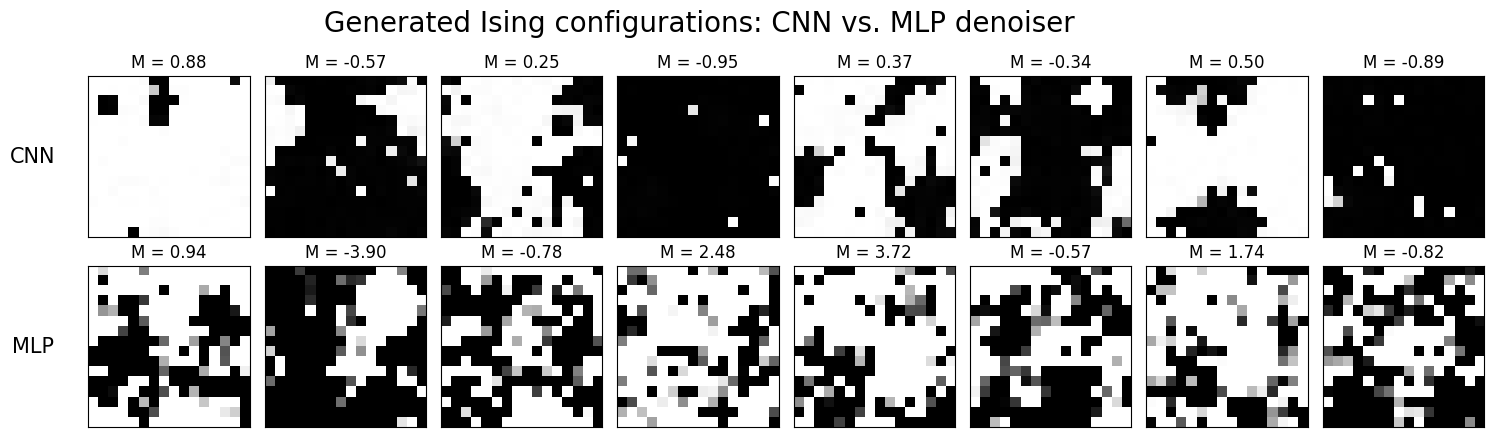

In [50]:
# side by side visual comparison
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))

for ax, c in zip(axes[0], gen_configs_cnn): # teh arguments are iterable
    ax.imshow(c, cmap='gray', vmin=-1, vmax=1)
    ax.set_title(f"M = {c.mean():.2f}", fontsize=12)
    ax.set_xticks([]); ax.set_yticks([])

for ax, c in zip(axes[1], gen_configs_mlp):
    ax.imshow(c, cmap='gray', vmin=-1, vmax=1)
    ax.set_title(f"M = {c.mean():.2f}", fontsize=12)
    ax.set_xticks([]); ax.set_yticks([])

# cleaner row labels: horizontal text, placed to the left of each row
axes[0, 0].set_ylabel("CNN", fontsize=15, rotation=0, labelpad=40, va='center')
axes[1, 0].set_ylabel("MLP", fontsize=15, rotation=0, labelpad=40, va='center')


plt.suptitle("Generated Ising configurations: CNN vs. MLP denoiser", fontsize=20)
plt.tight_layout(rect=[0.06, 0, 1, 1])
plt.show()

In [51]:
print(gen_configs_cnn.min(), gen_configs_cnn.max())
print(f"CNN: ∣x∣={np.abs(gen_configs_cnn).mean()}")

print(gen_configs_mlp.min(), gen_configs_mlp.max())
print(f"MLP: ∣x∣={np.abs(gen_configs_mlp).mean()}")

-1.1287878 1.1515902
CNN: ∣x∣=0.9904794692993164
-26.255777 34.842827
MLP: ∣x∣=5.535429000854492


The CNN denoiser generates configurations with large, coherent aligned domains closely resembling the real training data, while the MLP denoiser produces speckled, noisy configurations that lack this spatial coherence.

This is confirmed quantitatively: CNN outputs stay within [-1.12, 1.15] (mean $|x| \approx 0.99$, consistent with physical spins bounded in [-1, 1]), while MLP outputs range as wide as [-20, 22] (mean $|x| \approx 4.9$) which is almost over 5x the physically allowed magnitude, a clear and dramatic sign that the MLP has failed to learn the basic structure of the data.

---
## Part 2: Checking whether generated samples obey the physics

### Motivation

Visually inspecting a handful of generated lattices only tells us so much - the real test of a
generative model for physics is whether its samples are *statistically correct*, not just
plausible-looking. 

Here we generate a larger batch of configurations from the trained CNN denoiser and compare them against freshly simulated configurations at the same temperature, using two physical observables: the **magnetization distribution** (below $T_c$, this should be *bimodal*, with peaks near $\pm M_0$ and essentially nothing near zero, since the system spontaneously breaks the up/down symmetry independently in each run) and the **mean energy per spin** (a check that the generated configurations have the right degree of local spin alignment,
not just the right overall magnetization). 

If the CNN has genuinely learned the physics rather than memorizing superficial features of the training set, both statistics computed on generated samples should closely match those computed on real, simulated samples.

### Generating a large enough to get meaningful statistics - CNN

Generating samples from the CNN denoiser based model.

In [55]:
n_eval = 1500

# Generating with the trained CNN model
gen_configs_cnn_eval = sample(cnn_denoiser, n=n_eval, n_steps=n_steps, alphas=alphas, alpha_bar=alpha_bar, betas=betas, L=16)
print(gen_configs_cnn_eval.shape)

(1500, 16, 16)


Generating samples from the simulator.

In [56]:
# fresh simulated configs at the same T, for a fair "generated vs simulated" comparison
# those simulated configs were not trained on
sim_configs_eval = np.stack([ising_config(T_train, L=16) for _ in range(n_eval)])

print(sim_configs_eval.shape)

(1500, 16, 16)


In [ ]:
# ---- physical observables for the statistics battery (C.2) ----
def magnetization(c):
    """Signed magnetization per spin (mean of the +-1 lattice)."""
    return float(c.mean())

def energy_per_spin(c):
    """Mean energy per spin of a configuration."""
    return float(-(c * (np.roll(c, 1, 0) + np.roll(c, 1, 1))).mean())

### Magnetization: Generated vs. Simulated

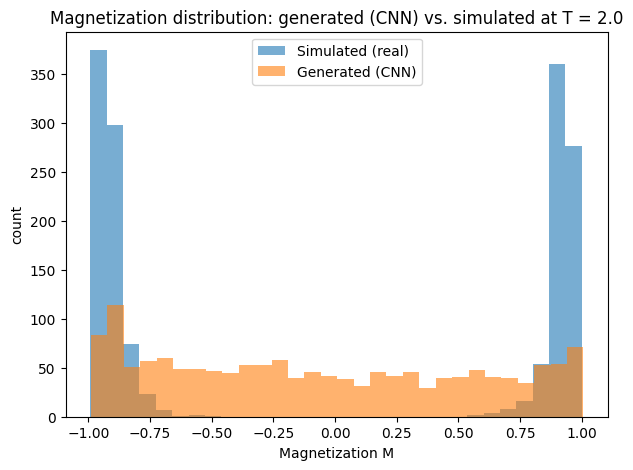

Simulated: Mean|M| = 0.911
Generated: Mean|M| = 0.550


In [63]:
# Magnetization
M_gen_cnn = np.array([magnetization(c) for c in gen_configs_cnn_eval])
M_sim = sim_configs_eval.mean(axis=(1, 2))

# Side-by-side magnetization histograms
plt.figure(figsize=(7, 5))
plt.hist(M_sim, bins=30, alpha=0.6, label='Simulated (real)')
plt.hist(M_gen_cnn, bins=30, alpha=0.6, label='Generated (CNN)')
plt.xlabel('Magnetization M')
plt.ylabel('count')
plt.legend()
plt.title(f'Magnetization distribution: generated (CNN) vs. simulated at T = {T_train}')
plt.show()

print(f"Simulated: Mean|M| = {np.abs(M_sim).mean():.3f}")
print(f"Generated: Mean|M| = {np.abs(M_gen_cnn).mean():.3f}")

The CNN-generated samples show a certain qualitative signature of the correct physics: there is some concentration of mass near $M \approx \pm 0.9$, matching the location of the simulated distribution's peaks. 

However, the generated distribution is noticeably **softer** than the physical accurate bimodal shape - a substantial fraction of generated configurations have magnetizations spread across the middle of the range ($-0.5 \lesssim M \lesssim 0.5$), a region where real simulated configurations should essentially never appear (since the system spontaneously and fully commits to o**ne ordered state or the other** below $T_c$).

This suggests the CNN has managed to learn the *qualitative* tendency toward order (large aligned domains, bias toward the extremes) but has not fully captured the *sharpness* of the phase separation - generating some configurations that are "partially ordered" rather than fully ordered. This is a partial success rather than either a full failure or a full reproduction of the physics, and is consistent with what a small model trained for a limited number of steps on limited data would be expected to produce.

### Energy per spin: generated vs. simulated

In [58]:
E_gen_cnn = np.array([energy_per_spin(c) for c in gen_configs_cnn_eval])
E_sim_cnn = np.array([energy_per_spin(c) for c in sim_configs_eval])

print(f"Simulated: Mean E/spin = {E_sim_cnn.mean():.3f}")
print(f"Generated: Mean E/spin = {E_gen_cnn.mean():.3f}")

Simulated: Mean E/spin = -1.746
Generated: Mean E/spin = -1.479


Each spin either agrees or disagrees with its neighbors. Agreeing (both up, or both down) is the physically favorable, lower-energy situation - Ising model is built on this ("neighbors want to align").

* If every spin agrees with all its neighbors (perfect order, T=0): energy per spin = −2 (as negative as it can get - maximally favorable).
* If spins are totally random (no preference at all, like at very high T): energy per spin ≈ 0 (agreements and disagreements roughly cancel out).
* Somewhere below $T_c$​ but above 0 (like our chosen temperature T=2.0): we will expect mostly agreement, with some thermal disagreement mixed in - so energy per spin sits somewhere in between, closer to −2 than to 0.

| | mean \|M\| | mean E/spin |
|---|---|---|
| Simulated (real) | 0.911 | -1.746 |
| Generated (CNN) | 0.55 | -1.479 |

Both observables tell a consistent story: the CNN-generated configurations are measurably less
ordered than real simulated ones, both globally (lower \|M\|) and locally (energy per spin closer
to 0, i.e. less neighbor-alignment than the true equilibrium value). This quantitatively confirms the qualitative "softness" (as also seen in the magnetization histogram): our CNN based model has learned the correct *direction* of the physics but still underestimates the *magnitude* of order the true equilibrium distribution exhibits.

This matches to the goal of this assignment - even a model which can generate configurations which have a *visual* match doesn't always provide physical statistical accuracy.

### Generating a large enough to get meaningful statistics - MLP

In [60]:
n_eval = 1500  

# # Generating with the trained MLP model
gen_configs_mlp_eval = sample(mlp_denoiser, n=n_eval, n_steps=n_steps, alphas=alphas, alpha_bar=alpha_bar, betas=betas, L=16)
print(gen_configs_mlp_eval.shape, sim_configs_eval.shape)

(1500, 16, 16) (1500, 16, 16)


### Magnetization: Generated vs. Simulated

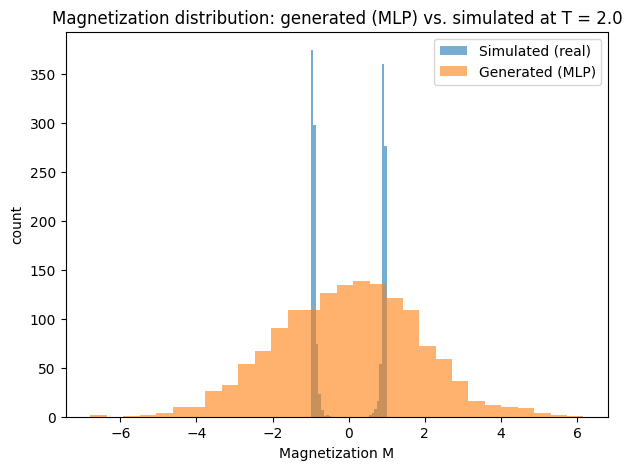

Simulated: Mean|M| = 0.911
Generated: Mean|M| = 1.471


In [64]:
# Magnetization
M_gen_mlp = np.array([magnetization(c) for c in gen_configs_mlp_eval])

# Side-by-side magnetization histograms
plt.figure(figsize=(7, 5))
plt.hist(M_sim, bins=30, alpha=0.6, label='Simulated (real)')
plt.hist(M_gen_mlp, bins=30, alpha=0.6, label='Generated (MLP)')
plt.xlabel('Magnetization M')
plt.ylabel('count')
plt.legend()
plt.title(f'Magnetization distribution: generated (MLP) vs. simulated at T = {T_train}')
plt.show()

print(f"Simulated: Mean|M| = {np.abs(M_sim).mean():.3f}")
print(f"Generated: Mean|M| = {np.abs(M_gen_mlp).mean():.3f}")

### CNN vs. MLP: Magnetization Distribution

Comparing all three magnetization distributions highlights effect of architecture of the two networks. The simulated distribution is sharply bimodal, tightly confined to $M \approx \pm0.9$, exactly as expected from the system below $T_c$. The CNN-generated distribution retains the qualitative bias toward the ordered extremes but is noticeably much softer, with a meaningful tail spreading toward the middle - and importantly, respects the physical bound $|M| \le 1$ (raw outputs stayed within roughly $[-1.12, 1.15]$).

The MLP-generated distribution fails, far more severely: it shows **no bimodal structure at all**, and spans roughly $[-6, 6]$ - 6x wider than the physically possible range for a
magnetization. This isn't merely "less accurate" than the CNN's result; it's a qualitatively
different kind of failure, consistent with the MLP having no architectural mechanism to encode the lattice's spatial/translational structure, and therefore no way to learn even the basic physical constraint that magnetization is bounded by construction.

### Energy per spin: generated vs. simulated

In [65]:
E_gen_mlp = np.array([energy_per_spin(c) for c in gen_configs_mlp_eval])
E_sim_mlp = np.array([energy_per_spin(c) for c in sim_configs_eval])

print(f"Simulated: Mean E/spin = {E_sim_mlp.mean():.3f}")
print(f"Generated: Mean E/spin = {E_gen_mlp.mean():.3f}")

Simulated: Mean E/spin = -1.746
Generated: Mean E/spin = -44.189


### Final comparison table

| | mean \|M\| | mean E/spin |
|---|---|---|
| Simulated (real) | 0.911 | -1.746 |
| Generated (CNN) | 0.55 | -1.479 |
| Generated (MLP) | (unbounded, spans ~[-6,6]) | -44.189 |

The energy-per-spin comparison makes the CNN/MLP gap even more dramatic than the magnetization comparison did. Real physical, ordered state spins, can have two values of energy per spin: $[-2, 0]$. The CNN's generated configurations respect this (-1.479, inside the physical range, which a bit less negative than the true equilibrium value). The MLP's configurations give a mean energy per spin of $-44.189$ - nearly two orders of magnitude outside the physically possible range. This arises because `energy_per_spin` involves a *product* of neighboring spin values, so considering the MLP's already-unphysical output, this observable supports the model's complete failure - unsurprising given the visual output.

Together, these results directly relate to the assignment's core point: a model whose samples look superficially plausible (the MLP's outputs do form visible spatial patterns) can nonetheless be wrong once checked against real physical constraints - underscoring why statistical validation, not visual inspection, is the real test of a physical generative model.

### Different models comparison

To ensure a fair comparison, the MLP denoiser was given a genuinely competitive attempt -
comparable training effort, and a larger hidden size (512, vs. the CNN's 128) to compensate for its lack of architectural inductive bias. Despite this, the MLP's generated configurations remained dramatically less physical (both visually and statistically), confirming that the gap comes from the *CNN's structural advantage* - translation-invariance and locality matching the lattice's actual physics - rather than simply a lack of training effort or capacity on the MLP's side.

---
## Part 3: Temperature aware generator

### Motivation

So far, the diffusion model only knows how to generate configurations at **one fixed temperature**, $T=2.0$ - it was never shown anything else, so it has no way to generate a more disordered configuration at $T=2.5$ for say, or a more strongly ordered one at $T=1.2$. Thus, so far we worked with **Unconditional** diffusion model - a model which learns to denoise samples from one distribution; its denoiser takes the noisy field $x_t$ and the diffusion step $t$ as inputs.

Physically, temperature is what actually *controls* the Ising model's behavior: it's the single parameter that takes the system from strongly ordered ($T \ll T_c$, large $|M|$) through the critical point $T_c \approx 2.269$ (where the order parameter vanishes continuously) to fully disordered ($T \gg T_c$, $|M| \to 0$). A model that only works at one $T$ has only learned one frozen snapshot out of a much richer underlying physical story - the transition itself.

To make it **conditional on $T$**, we follow the exact same idea already used for the diffusion *timestep* $t$ (which is in that case - the amount of noise, not temperature which will be addressed as $T$): since the denoiser has no built-in notion of "temperature," we simply *tell it*, by feeding $T$ in as an extra broadcast input channel, alongside the noisy lattice and the timestep. Trained on configurations spanning **a whole range of $T$**, the network can then learn how the physics (and therefore the generated configurations) should change *continuously* with $T$, giving one model that generates correctly across the entire range, including **through the transition itself.**

### Creating the temperature aware generator

The training data will have a range of $T \in [1.0,3.0]$. We sample temperatures across the ordered phase, through $T_c \approx 2.269$, and into the disordered phase, so the model can learn how the physics **changes continuously with $T$**.

Near $T_c$, the system will exhibit a **critical slowing down** - correlation times will grow near that temperature, so more Monte-Carlo sweeps are needed to reach true equilibrium. We will scale `n_sweeps` up in a window around $T_c$ to keep the data near the transition reliable.

In [71]:
# simulating physical configuration with a range of temperatures
Tc = 2.269
T_min, T_max = 1.0, 3.0
n_temps = 21
n_per_temp = 100 # enough samples at each T to average over for smoothness later

T_values = np.linspace(T_min, T_max, n_temps)

configs_list = []
T_labels_list = []

for T in T_values: # for each of the 21 temperatures
    # extra equilibration sweeps near Tc, where correlation times grow (critical slowing down to reach equilibrium)
    n_sweeps = int(120 + 300 * np.exp(-((T - Tc) / 0.3) ** 2)) # baseline + a width controlled Gaussian bump centered at Tc, which slowly decays toward 0 as T grows further from center.
    for _ in range(n_per_temp): # 100 configs per temperature (to later average on)
        configs_list.append(ising_config(T, L=16, n_sweeps=n_sweeps))
        T_labels_list.append(T)

configs_cond = np.stack(configs_list)
T_labels_cond = np.array(T_labels_list)

print(configs_cond.shape, T_labels_cond.shape)   # should be (2100, 16, 16) (2100,)

(2100, 16, 16) (2100,)


We'll now run a sanity check - plot mean $|M|$ vs $T$ from this new dataset, to confirm it actually shows the expected physics ($|M| \pm 1$ near $T=1$, dropping through near 0 by $T=3$).

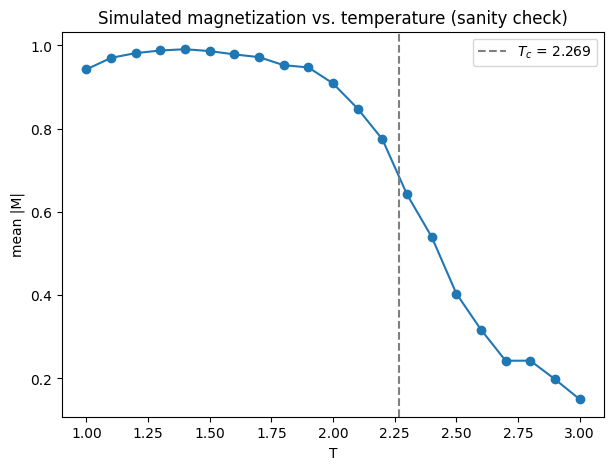

In [73]:
M_by_T = []
for T in T_values: # looping over the 21 different temperature
    mask = np.isclose(T_labels_cond, T) # True exactly where a config's label matches this T
    M_by_T.append(np.abs(configs_cond[mask].mean(axis=(1,2))).mean()) # only those ~100 matching configs, everything else dropped

plt.figure(figsize=(7,5))
plt.plot(T_values, M_by_T, 'o-')
plt.axvline(Tc, color='gray', linestyle='--', label=f'$T_c$ = {Tc:.3f}')
plt.xlabel('T')
plt.ylabel('mean |M|')
plt.title('Simulated magnetization vs. temperature (sanity check)')
plt.legend()
plt.show()

These graph exhibits magnetization vs temperature with 21 different temperatures - for each temperature we took 100 samples and averaged them all down to a single value of magnetization - yielding 21 magnetization points - each for every single temperature.

It appears that the sanity check went good so we can continue.

### Temperature aware CNN denoiser

We now add an additional input channel for the temperature $T$, making the denoiser temperature conditional. We do so the same way we did for the time stamp $t$.

In [84]:
class CondConvDenoiser(nn.Module):
    def __init__(self, hidden=64, T_min=1.0, T_max=3.0):
        super().__init__()
        self.T_min = T_min
        self.T_max = T_max
        self.net = nn.Sequential(
            nn.Conv2d(3, hidden, kernel_size=3, padding=1, padding_mode='circular'), nn.SiLU(),
            nn.Conv2d(hidden, hidden, kernel_size=3, padding=1, padding_mode='circular'), nn.SiLU(),
            nn.Conv2d(hidden, hidden, kernel_size=3, padding=1, padding_mode='circular'), nn.SiLU(),
            nn.Conv2d(hidden, 1, kernel_size=3, padding=1, padding_mode='circular'),
        )

    def forward(self, x, t, n_steps, T_cond):
        B, _, L, _ = x.shape
        t_channel = (t.float() / n_steps).view(B, 1, 1, 1).expand(B, 1, L, L)
        T_norm = (T_cond.float() - self.T_min) / (self.T_max - self.T_min) # maps [T_min, T_max] -> [0, 1], neural networks generally train better when their inputs are roughly on the order of 1
        T_channel = T_norm.float().view(B, 1, 1, 1).expand(B, 1, L, L) # broadcast T the same way as t
        h = torch.cat([x, t_channel, T_channel], dim=1) # 3 channels stacked, not 2
        return self.net(h)

The new training loop - Every random batch (idx = torch.randint(...)) needs to grab both the configs and their matching temperature labels, using the same idx for both - since 'X[idx] 'and 'T_labels[idx]' need to stay paired (config #37 must be matched with temperature-label #37, not some other one). Then that batch's temperatures get passed into model(...) as the new T_cond argument.

In [85]:
def train_denoiser_cond(model, X, T_labels, alpha_bar, n_steps, n_epochs=3000, batch_size=128, lr=2e-3, print_every=500):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for epoch in range(n_epochs):
        opt.zero_grad()
        idx = torch.randint(0, len(X), (batch_size,))
        x0 = X[idx]
        T_batch = T_labels[idx]                       # NEW: grab matching temperature labels, same idx
        t = torch.randint(0, n_steps, (batch_size,))
        noise = torch.randn_like(x0)
        ab = alpha_bar[t].view(-1, 1, 1, 1)
        xt = torch.sqrt(ab) * x0 + torch.sqrt(1 - ab) * noise
        pred_noise = model(xt, t, n_steps, T_batch)    # NEW: pass T_batch through to the model
        loss = ((pred_noise - noise) ** 2).mean()
        loss.backward()
        opt.step()
        if epoch % print_every == 0:
            print(f"epoch {epoch:4d} | noise-prediction MSE {loss.item():.4f}")
    print(f"final MSE {loss.item():.4f}")
    return model

In [86]:
# This training function only accepts the configurations and the temperature ('T_labels') as tensors
X_cond = torch.tensor(configs_cond, dtype=torch.float32).unsqueeze(1) # (2100, 1, 16, 16)
T_labels_tensor = torch.tensor(T_labels_cond, dtype=torch.float32) # (2100,)

In [87]:
model_cond = CondConvDenoiser(hidden=128, T_min=1.0, T_max=3.0)
model_cond = train_denoiser_cond(model_cond, X_cond, T_labels_tensor, alpha_bar, n_steps,
                                  n_epochs=3000, batch_size=128, lr=1e-3, print_every=500)

epoch    0 | noise-prediction MSE 1.0004
epoch  500 | noise-prediction MSE 0.0673
epoch 1000 | noise-prediction MSE 0.0667
epoch 1500 | noise-prediction MSE 0.0604
epoch 2000 | noise-prediction MSE 0.0581
epoch 2500 | noise-prediction MSE 0.0703
final MSE 0.0483


In [90]:
# Save the model's state dictionary (Recommended)
torch.save(model_cond.state_dict(), 'model_cond_weights.pth')

In [92]:
# Save the entire model object (Less recommended)
torch.save(model_cond, 'model_cond_full.pth')

# Load the entire model later
# loaded_model = torch.load('model_cond_full.pth')
# loaded_model.eval()

### Generating samples from the temperature conditional model

In [ ]:
# Generating function
@torch.no_grad()
def sample_cond(model, n, T_target, n_steps, alphas, alpha_bar, betas, L=16):
    x = torch.randn(n, 1, L, L) # n separate 16×16 grids, all noise, no structure
    T_cond = torch.full((n,), T_target) # same T for every example, every step
    for t in reversed(range(n_steps)): # one full pass through every timestep, but in reverse order
        tt = torch.full((n,), t) # repeating *this* current t value n times for the whole batch of configs - one copy per example in the batch, so it can be passed into model(...), which expects one t value per example
        pred = model(x, tt, n_steps, T_cond) # pass T_cond through
        a, ab, b = alphas[t], alpha_bar[t], betas[t]
        x = (1 / torch.sqrt(a)) * (x - (b / torch.sqrt(1 - ab)) * pred)
        if t > 0:
            x = x + torch.sqrt(b) * torch.randn_like(x)# adding fresh randomness back in, except on the last step
    return x.numpy().reshape(n, L, L) # after all the steps, 'x' is the noiseless config

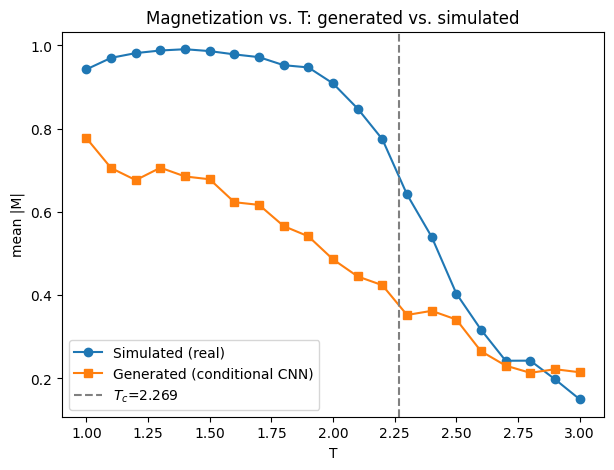

In [ ]:
M_gen_by_T = []
E_gen_by_T = []
for T in T_values:
    gen = sample_cond(model_cond, n=100, T_target=T, n_steps=n_steps, alphas=alphas, alpha_bar=alpha_bar, betas=betas)
    M_gen_by_T.append(np.abs(gen.mean(axis=(1,2))).mean())
    E_gen_by_T.append(np.mean([energy_per_spin(c) for c in gen]))

#### Full Magnetization Curve $|M|(T)$

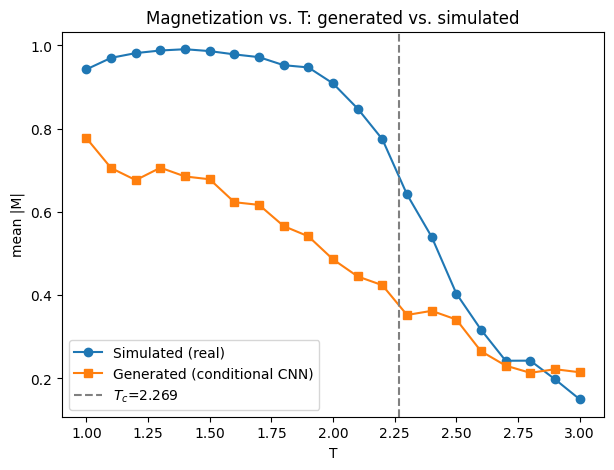

In [98]:
plt.figure(figsize=(7,5))
plt.plot(T_values, M_by_T, 'o-', label='Simulated (real)')
plt.plot(T_values, M_gen_by_T, 's-', label='Generated (conditional CNN)')
plt.axvline(Tc, color='gray', linestyle='--', label=f'$T_c$={Tc:.3f}')
plt.xlabel('T'); plt.ylabel('mean |M|'); plt.legend()
plt.title('Magnetization vs. T: generated vs. simulated')
plt.show()

##### Magnetization vs. Temperature

Comparing the conditional CNN's generated samples against freshly simulated configurations
*across the full temperature range* shows that the model has successfully learned the
**qualitative shape** of the phase transition: the generated magnetization curve decreases
smoothly with $T$ and shows a visible steepening near $T_c \approx 2.269$, correctly
distinguishing the ordered phase ($T < T_c$) from the disordered phase ($T > T_c$) using **a single trained model.**

Below $T_c$ (the **ordered phase**), there is some physical inaccuracy - the generated curve sits systematically below the true simulated curve (at $T=1.0$: simulated $|M|\approx0.94$ vs. generated $|M|\approx0.78$), consistent with the same under-confidence ("softness") seen in the single-temperature CNN result. Above $T_c$, the two curves converge much more closely, suggesting the model reproduces the disordered phase more accurately than the ordered phase. Near $T_c$ itself, the two curves are reasonably close, indicating the model has correctly localized the transition even where it doesn't perfectly reproduce the degree of order on either side.

#### Full Energy Curve $E(T)$

In [99]:
# simulating the data
E_by_T = []
for T in T_values:
    mask = (T_labels_cond == T)
    E_by_T.append(np.mean([energy_per_spin(c) for c in configs_cond[mask]]))

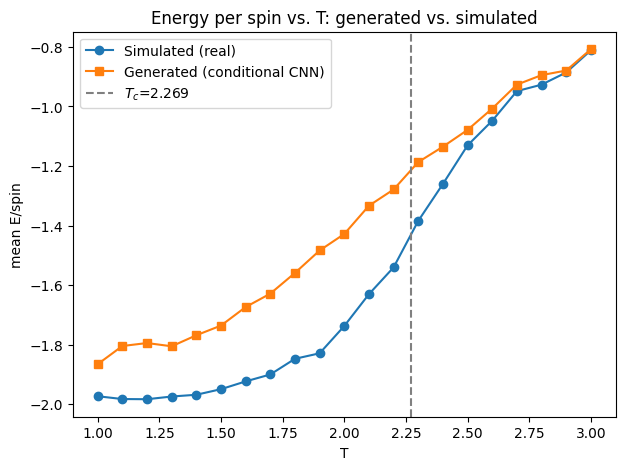

In [100]:
plt.figure(figsize=(7,5))
plt.plot(T_values, E_by_T, 'o-', label='Simulated (real)')
plt.plot(T_values, E_gen_by_T, 's-', label='Generated (conditional CNN)')
plt.axvline(Tc, color='gray', linestyle='--', label=f'$T_c$={Tc:.3f}')
plt.xlabel('T'); plt.ylabel('mean E/spin'); plt.legend()
plt.title('Energy per spin vs. T: generated vs. simulated')
plt.show()

##### Energy Per Spin vs. Temperature

The generated curve has the right shape - lower energy at low T, consistently rising toward $0$ as the temperature rises, meaning that the conditional model learned and implements the physical rules - at lower temperatures, the system is ordered, spins align and the energy is lower. As the temperature rises, more spins are canceling each other out, energy gets closer to 0. 

Near and above $T_c$, there is clear change right at the transition, however below $T_c$, the generated energy is always a bit higher (less negative) than the real value, by about 0, indicating less order if it were a genuine physical structure. This means the generated configs have *a bit less alignment* between neighbors than simulated ones, at every $T$ below $T_c$. 

Above $T_c$, and as the temperature rises, the generated and real curves are closer - meaning that the energy per spin results agree with the magnetization results - the model's problem is specific to how strongly ordered it makes the **low temperature** configs, not a general problem with using $T$ as an input.

---
## Hyperparameters

- Simulated data at `T=2.0`, safely below `T_c≈2.269` so configs are clearly in the ordered/bimodal regime. Lattice `16×16`, which is big enough to show real structure, small enough to train fast. 2000 configs - enough training data for a small diffusion model at this scale.
- Diffusion: 300 steps - enough steps for a smooth noise-to-data process without being needlessly slow. Linear beta schedule 1e-4 → 0.04, a standard mild-to-moderate noise ramp.
- CNN denoiser: `hidden=64`, circular padding to match the simulator's periodic boundary conditions (so the model doesn't invent a fake edge).
- MLP denoiser: `hidden=512` (compensating with width for having no spatial structure), used as the weaker baseline since it throws away the grid layout.
- Training (both): Adam, `lr=1e-3`, 3000 epochs (diffusion models need more steps than a simple regressor to learn well), batch `128`.
- Temperature-conditional model: trained on $`T \in [1.0, 3.0]`$ to cover both phases and the transition. 21 temperatures × 100 samples each for smooth statistics. Extra sampling near `T_c` because that region has slower equilibration (critical slowing down), so it needs more Monte Carlo sweeps to get reliable samples.

---
## Self-assessment

**What worked well:**
The diffusion general pipeline works. Starting from pure noise, the CNN denoiser can generate Ising configs that look like a real physical system - big aligned domains, with very little random noise. The training loop and the reverse sampling loop both work as expected, and match the math from the forward process.

**CNN vs MLP:**
This was the clearest result in the project. Visually, the CNN generates clear and useful configs while the MLP did not provide. Statistically, the MLP did much worse than the CNN which came the closest among the two to real physics (mean|M| = 0.569 vs real 0.911, mean E/spin = -1.479 vs real -1.746). The MLP's magnetization is not even bounded to [-1,1] like a real spin average should be, and its energy per spin comes out at $\approx -44.2$. Even though we gave the MLP a real chance (bigger hidden size, more training), it still failed badly. This shows the gap is not about training effort - it's about the **architecture**. The convolution treats the lattice's local, periodic structure. The MLP does not consider the structure, and that difference matters a lot for this kind of physical data.

**Where the CNN falls short:**
Though it yields much better results the the MLP, the CNN is not perfect. It gets the right *shape* - bimodal magnetization, negative energy, same general trend - but it is "too soft": too many generated configs sit in the middle of the magnetization range, where real physics almost never puts them. So the model learned that the system prefers order, but not how strongly it should commit to one state.

**The conditional model:**
The conditional model (with $T$ as extra input, same trick as $t$) learned the shape of the phase transition, using one single model across a whole range of temperatures. Both $M(T)$ and $E(T)$ curves have the right general shape, and match well above $T_c$ (disordered phase), however, below $T_c$ (ordered phase), the model is again "too soft" - same problem as before, just now showing up clearly across a whole range of temperatures and not just at one.

**Do I trust this model?**
For the general shape of the physics - yes, it's a real result: the CNN learned real spatial
structure, real bimodality, and a real phase transition, using nothing but noise and a trained network. For exact quantitative accuracy - no, especially in the ordered phase, where the model underestimates how strongly the system should order. If I had more time, more training and a bigger model would probably help close this gap, since the model already shows it's learning the right direction, just not strongly enough yet.